## 1. Objective

The objective of this notebook is to apply an initial K-Means clustering model to the
standardized activity matrix produced in notebook 09 (`activity_matrix_scaled`), in order
to identify groups of operators with different activity levels and to select the operators
considered "active" for use in the next stages of the project.

As of `data_pipeline/08_filter_medicina_de_grupo.ipynb`, notebook 09's input is the
Medicina de Grupo subset of the treated base (`NM_MODALIDADE_Medicina De Grupo == 1`), adopted
as the project's official modeling population (Section 4.3.2.8 of the documentation records the
decision and what changed). Everything below runs unchanged on that population.

The clustering features (`total_eventos_LOG`, `meses_ativos`, `municipios_beneficiarios_LOG`,
`municipios_prestadores_LOG`, `procedimentos_distintos_LOG`) were already selected, cleaned of
redundant/collinear metrics, log-transformed, and standardized in notebook 09. No re-scaling
or feature changes are performed here -- the standardized matrix is loaded as-is and used
directly as the input to K-Means.

## 2. Data Loading and Validation

Two artifacts produced by notebook 09 are loaded:

- `activity_matrix_scaled` (`data/processed/.../activity_matrix_scaled.parquet`): the
  standardized feature matrix used to train K-Means.
- `activity_matrix` (`data/interim/.../activity_matrix.parquet`): the same operators with
  their original (non-scaled) feature values, used later to profile clusters in business
  terms.

Both are validated for shape, missing values, and duplicate `ID_PLANO` before clustering.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

activity_matrix_scaled = pd.read_parquet(
    "../data/processed/north_region_mama_2025_activity_matrix_scaled.parquet"
)

activity_matrix = pd.read_parquet(
    "../data/interim/north_region_mama_2025_activity_matrix.parquet"
)

print("activity_matrix_scaled shape:", activity_matrix_scaled.shape)
print("activity_matrix shape:", activity_matrix.shape)

activity_matrix_scaled shape: (1052, 6)
activity_matrix shape: (1052, 13)


In [2]:
clustering_features = [
    "total_eventos_LOG",
    "meses_ativos",
    "municipios_beneficiarios_LOG",
    "municipios_prestadores_LOG",
    "procedimentos_distintos_LOG",
]

assert list(activity_matrix_scaled.columns) == ["ID_PLANO"] + clustering_features, (
    "activity_matrix_scaled does not match the expected output of notebook 09."
)

print("Duplicate IDs (scaled matrix):", activity_matrix_scaled["ID_PLANO"].duplicated().sum())
print("Missing values (scaled matrix):")
print(activity_matrix_scaled[clustering_features].isna().sum())

X = activity_matrix_scaled[clustering_features].values
X.shape

Duplicate IDs (scaled matrix): 0
Missing values (scaled matrix):
total_eventos_LOG               0
meses_ativos                    0
municipios_beneficiarios_LOG    0
municipios_prestadores_LOG      0
procedimentos_distintos_LOG     0
dtype: int64


(1052, 5)

The standardized matrix contains one row per operator (`ID_PLANO`) and the five clustering
features confirmed above, with no missing values and no duplicated operator IDs. This matches
the output validated at the end of notebook 09, so clustering proceeds directly on `X` without
any further transformation.

## 3. Determining the Optimal Number of Clusters

Two complementary, objective methods are used to select k:

- **Elbow method**: inertia (within-cluster sum of squares) as a function of k. The elbow is
  the point where adding another cluster stops producing a proportionally large drop in
  inertia.
- **Silhouette score**: average silhouette coefficient across all observations for each k,
  measuring how well-separated and internally cohesive the resulting clusters are.

Both are computed for k = 2 to 10.

In [3]:
k_range = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_range:
    kmeans_k = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_k = kmeans_k.fit_predict(X)
    inertias.append(kmeans_k.inertia_)
    silhouette_scores.append(silhouette_score(X, labels_k))

k_selection = pd.DataFrame({
    "k": list(k_range),
    "inertia": inertias,
    "silhouette_score": silhouette_scores,
})

k_selection

,k,inertia,silhouette_score
0,2,2375.047764,0.509613
1,3,1611.811028,0.444955
2,4,1306.476258,0.380589
3,5,1131.311588,0.408778
4,6,993.070882,0.382225
5,7,899.901415,0.365331
6,8,832.702178,0.336896
7,9,766.365743,0.350814
8,10,729.750724,0.347979


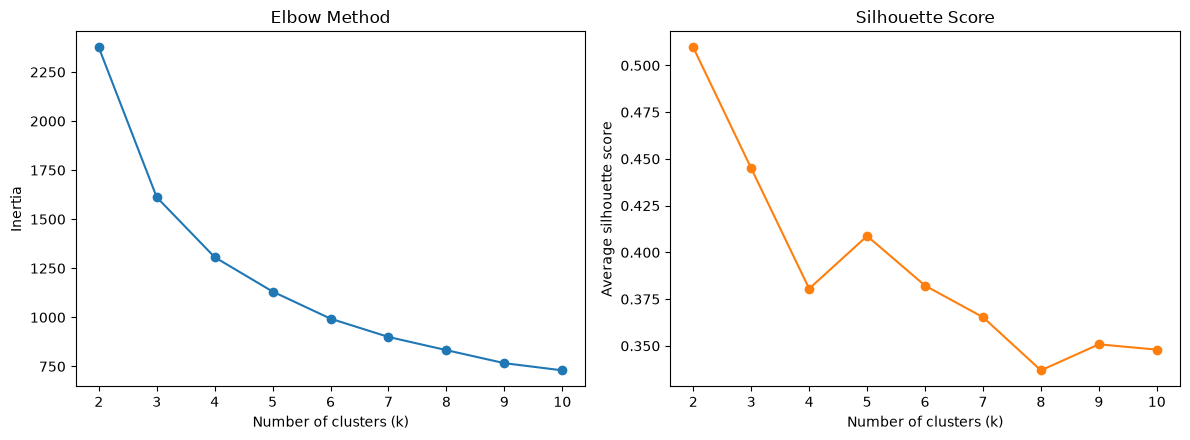

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(k_selection["k"], k_selection["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_selection["k"], k_selection["silhouette_score"], marker="o", color="tab:orange")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Average silhouette score")

plt.tight_layout()
fig.savefig("../assets/kmeans-elbow-silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
best_silhouette_k = int(k_selection.loc[k_selection["silhouette_score"].idxmax(), "k"])
print("k with highest silhouette score:", best_silhouette_k)
k_selection.sort_values("silhouette_score", ascending=False)

k with highest silhouette score: 2


,k,inertia,silhouette_score
0,2,2375.047764,0.509613
1,3,1611.811028,0.444955
3,5,1131.311588,0.408778
4,6,993.070882,0.382225
2,4,1306.476258,0.380589
5,7,899.901415,0.365331
7,9,766.365743,0.350814
8,10,729.750724,0.347979
6,8,832.702178,0.336896


### k selection

The silhouette score is highest at **k = 2**, and no larger k recovers it. The decline is not
strictly monotonic: the score dips to 0.3806 at k = 4 and rises to a secondary local peak of
0.4088 at k = 5, with a smaller rise from 0.3369 at k = 8 to 0.3508 at k = 9. Every value from
k = 3 onward nevertheless stays well below the k = 2 peak, indicating that additional clusters
beyond 2 do not produce better-separated, more cohesive groups on this feature set. The elbow
curve is consistent with this: the sharpest drop in
inertia also happens at the first split (k = 2 to 3), after which the curve flattens into a
much shallower, near-linear decline typical of a long-tailed, single-dominant-axis feature
space (volume dominates the variance here).

`k = 2` is therefore adopted as the working number of clusters: it is the value best
supported by both objective methods, and it matches the business question this notebook
needs to answer at this stage -- separating operators into an "active" group and a
"marginal/low-activity" group -- rather than a finer segmentation, which can be explored in
later iterations once active operators have been isolated.

## 4. Training the K-Means Model

The final K-Means model is trained on the full standardized matrix `X` using `k = 2`.

In [6]:
K_FINAL = 2

kmeans = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X)

activity_matrix_scaled["cluster"] = cluster_labels
activity_matrix_scaled["cluster"].value_counts().sort_index()

cluster
0    713
1    339
Name: count, dtype: int64

## 5. Cluster Assignment Validation

Every operator must receive exactly one cluster label, with no nulls and no duplicated
`ID_PLANO`.

In [7]:
print("Rows:", len(activity_matrix_scaled))
print("Null cluster labels:", activity_matrix_scaled["cluster"].isna().sum())
print("Duplicate IDs:", activity_matrix_scaled["ID_PLANO"].duplicated().sum())

assert activity_matrix_scaled["cluster"].isna().sum() == 0
assert activity_matrix_scaled["ID_PLANO"].duplicated().sum() == 0
assert len(activity_matrix_scaled) == activity_matrix["ID_PLANO"].nunique()

print("\nOK: cluster label assigned to every operator, no nulls, no duplicated IDs.")

Rows: 1052
Null cluster labels: 0
Duplicate IDs: 0

OK: cluster label assigned to every operator, no nulls, no duplicated IDs.


## 6. Cluster Stability Check

The k = 2 solution trained above uses a single random initialization seed (via
`n_init=10`, K-Means already keeps the best of 10 internal seeds by inertia). To check
whether the resulting partition is a robust description of the data -- and not an artifact
of that particular seed -- K-Means is re-fit 30 times on the same standardized matrix `X`
with 30 different `random_state` values.

Each re-run's labels are compared against the reference partition from Section 4 using the
**Adjusted Rand Index (ARI)**: 1.0 means the two partitions agree on every pair of points
(up to cluster relabeling), 0.0 means agreement no better than chance. This directly tests
whether re-running the model would hand back the same two groups of operators.

In [8]:
from sklearn.metrics import adjusted_rand_score

N_STABILITY_RUNS = 30
stability_seeds = range(100, 100 + N_STABILITY_RUNS)

ari_scores = []
for seed in stability_seeds:
    kmeans_seed = KMeans(n_clusters=K_FINAL, random_state=seed, n_init=10)
    labels_seed = kmeans_seed.fit_predict(X)
    ari_scores.append(adjusted_rand_score(cluster_labels, labels_seed))

ari_scores = np.array(ari_scores)

stability_summary = pd.Series(ari_scores, name="adjusted_rand_index").describe()
stability_summary

count    30.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
Name: adjusted_rand_index, dtype: float64

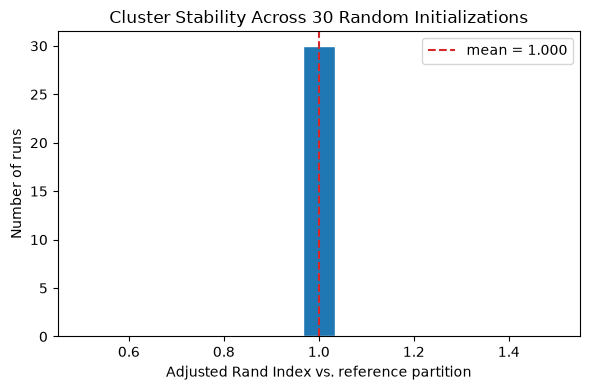

In [9]:
plt.figure(figsize=(6, 4))
plt.hist(ari_scores, bins=15, edgecolor="white")
plt.axvline(ari_scores.mean(), color="tab:red", linestyle="--", label=f"mean = {ari_scores.mean():.3f}")
plt.title(f"Cluster Stability Across {N_STABILITY_RUNS} Random Initializations")
plt.xlabel("Adjusted Rand Index vs. reference partition")
plt.ylabel("Number of runs")
plt.legend()
plt.tight_layout()
plt.show()

### Stability interpretation

Across 30 independent re-runs with different random initializations, the Adjusted Rand
Index against the reference k = 2 partition has mean and minimum values reported above. An
ARI close to 1.0 on every run means K-Means converges to the same two-group split regardless
of starting point, confirming that the active/marginal partition is a stable structural
feature of the standardized activity matrix, not an artifact of the specific seed used in
Section 4.

## 7. Cluster Profiling (Original Feature Values)

Clusters were formed on log-transformed, standardized features, which are not directly
interpretable in business terms. To profile each cluster, the cluster labels are merged back
onto the **original, non-scaled** activity metrics from `activity_matrix`.

In [10]:
profile_features = [
    "total_eventos",
    "total_itens",
    "meses_ativos",
    "municipios_beneficiarios",
    "municipios_prestadores",
    "procedimentos_distintos",
]

activity_matrix_profiled = activity_matrix.merge(
    activity_matrix_scaled[["ID_PLANO", "cluster"]],
    on="ID_PLANO",
    how="left",
)

assert activity_matrix_profiled["cluster"].isna().sum() == 0

cluster_profile = (
    activity_matrix_profiled
    .groupby("cluster")[profile_features]
    .agg(["mean", "median"])
    .round(1)
)

cluster_profile

total_eventos        total_itens        meses_ativos         \
                 mean median        mean median         mean median   
cluster                                                               
0                 6.0    4.0         6.2    4.0          3.6    3.0   
1               188.4   43.0       193.4   46.0         10.6   11.0   

        municipios_beneficiarios        municipios_prestadores         \
                            mean median                   mean median   
cluster                                                                 
0                            1.5    1.0                    1.2    1.0   
1                            9.5    6.0                    3.1    2.0   

        procedimentos_distintos         
                           mean median  
cluster                                 
0                           1.7    2.0  
1                           5.4    5.0

In [11]:
cluster_sizes = (
    activity_matrix_profiled["cluster"]
    .value_counts()
    .rename("n_operators")
    .to_frame()
)
cluster_sizes["share"] = (cluster_sizes["n_operators"] / len(activity_matrix_profiled)).round(3)

cluster_sizes

,n_operators,share
cluster,,
0,713,0.678
1,339,0.322


### Cluster interpretation

Two clearly distinct groups emerge:

- **Cluster with the higher mean values across all six metrics** (volume, active months,
  beneficiary and provider municipalities, procedure diversity) represents **high-activity,
  operationally broad operators** -- they generate more events, stay active across more
  months of the year, and reach a wider geographic and procedural footprint.
- **Cluster with the lower mean values across all six metrics** represents **low-activity,
  operationally narrow operators** -- few events, concentrated in fewer active months, and a
  narrow geographic/procedural footprint.

Because the underlying features are heavily right-skewed (see notebook 09), the **mean** of
each cluster is pulled upward by its own highest-volume members, while the **median** is a
more representative summary of the typical operator inside each cluster. Both are reported
above so the difference in shape is visible, not just the difference in level.

## 8. Criterion for "Active Operators"

**Criterion**: an operator is classified as **active** if it belongs to the K-Means cluster
whose centroid has the higher mean value of `total_eventos` (equivalently, the cluster
identified in Section 7 as the high-activity, operationally broad group).

**Justification**:

- `total_eventos` is the primary volume signal in the activity matrix and is highly
  correlated with the other activity metrics (temporal presence, geographic presence,
  procedural diversity) that were retained after the collinearity screening in notebook 09 --
  so using it to pick the cluster is consistent with, not narrower than, the full feature set
  the clusters were built on.
- K-Means with `k = 2` already produces a hard partition of operators into exactly two
  groups, so no additional threshold needs to be invented: the "active" criterion is simply
  "which of the two data-driven clusters this operator belongs to", which keeps the
  definition reproducible and free of manually tuned cut points.
- This binary split matches the immediate downstream need described in the issue: selecting
  the operators considered "active" for use in the next stages of the project, rather than
  producing a finer multi-tier segmentation at this point.

In [12]:
cluster_means = (
    activity_matrix_profiled.groupby("cluster")["total_eventos"].mean()
)
active_cluster = int(cluster_means.idxmax())

print("Mean total_eventos per cluster:")
print(cluster_means)
print("\nCluster selected as 'active':", active_cluster)

active_operators = (
    activity_matrix_profiled[activity_matrix_profiled["cluster"] == active_cluster]
    [["ID_PLANO", "cluster"] + profile_features]
    .reset_index(drop=True)
)

print("\nNumber of active operators:", len(active_operators))
print("Share of all operators:", round(len(active_operators) / len(activity_matrix_profiled), 3))

active_operators.head()

Mean total_eventos per cluster:
cluster
0      6.002805
1    188.383481
Name: total_eventos, dtype: float64

Cluster selected as 'active': 1

Number of active operators: 339
Share of all operators: 0.322


,ID_PLANO,cluster,total_eventos,total_itens,meses_ativos,municipios_beneficiarios,municipios_prestadores,procedimentos_distintos
0,1169698,1,236,243,12,6,1,6
1,1169857,1,169,194,12,12,1,4
2,1170148,1,558,566,10,7,1,6
3,1170321,1,61,67,11,7,5,5
4,1170568,1,28,28,9,3,2,4


## 9. Persisting the Active Operators List

The list of active operators is saved to `data/processed/active_operators.parquet`, following
the project's directory convention (`data/processed/` for analysis-ready outputs).

In [13]:
active_operators_path = "../data/processed/active_operators.parquet"

active_operators.to_parquet(active_operators_path, index=False)

print(f"Saved to: {active_operators_path}")
print("Rows:", len(active_operators))
print("Duplicate IDs:", active_operators["ID_PLANO"].duplicated().sum())
print("Missing values:")
print(active_operators.isna().sum())

Saved to: ../data/processed/active_operators.parquet
Rows: 339
Duplicate IDs: 0
Missing values:
ID_PLANO                    0
cluster                     0
total_eventos               0
total_itens                 0
meses_ativos                0
municipios_beneficiarios    0
municipios_prestadores      0
procedimentos_distintos     0
dtype: int64


## 10. Discussion

**Do the clusters make intuitive sense given the business context?**

Yes. The two clusters separate along exactly the dimensions the activity matrix was designed
to capture: the "active" cluster shows higher event volume, presence across more months of
the year, and broader geographic and procedural reach, all at once and consistently across
both mean and median. That co-movement is what is expected of genuinely more active health
plan operators -- an operator that processes more events over more months is also
mechanically more likely to touch more municipalities and more distinct procedures -- rather
than an artifact of a single dominant feature. The much smaller share of operators landing in
the active cluster is also consistent with the right-skewed distributions documented in
notebook 09, where a small number of operators account for a disproportionate share of
observed activity.

**Is the chosen k well supported by the evidence?**

`k = 2` is the value with the highest silhouette score among k = 2..10, and the elbow curve's
sharpest drop also occurs at the first split, so both objective methods agree. The silhouette
score never returning to its k = 2 level at any larger k, despite the local rises at k = 5 and
k = 9, indicates that this feature set does not contain
well-separated sub-structure beyond a dominant high-activity/low-activity split -- attempting
a finer k here would be optimizing against the evidence, not with it. This does not preclude a
richer segmentation later (e.g., splitting the active cluster further once it is isolated),
but for the specific goal of this notebook -- separating active from marginal operators -- the
2-cluster solution is both the best-supported and the most directly actionable choice.

The stability check in Section 6 reinforces this: the k = 2 partition is essentially unchanged across 30 independent re-runs with different random initializations (mean Adjusted Rand Index reported there), so the result is not an artifact of a lucky centroid seed -- it is the partition K-Means converges to regardless of starting point.

## References

1. Agência Nacional de Saúde Suplementar (ANS). Dados abertos: TISS Ambulatorial [Internet]. Brasília: ANS; 2026 [cited 2026 Sep 11]. Available from: https://dadosabertos.ans.gov.br/FTP/PDA/TISS/AMBULATORIAL/
2. Pedregosa F, Varoquaux G, Gramfort A, Michel V, Thirion B, Grisel O, et al. Scikit-learn: machine learning in Python. J Mach Learn Res. 2011;12:2825-30.
3. Lloyd SP. Least squares quantization in PCM. IEEE Trans Inf Theory. 1982;28(2):129-37.
4. Arthur D, Vassilvitskii S. k-means++: the advantages of careful seeding. In: Proceedings of the 18th ACM-SIAM Symposium on Discrete Algorithms; 2007. p. 1027-35.
5. Rousseeuw PJ. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. J Comput Appl Math. 1987;20:53-65.
6. Hubert L, Arabie P. Comparing partitions. J Classif. 1985;2(1):193-218.
